In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving sales_data_sample.csv to sales_data_sample.csv


In [ ]:
df = pd.read_csv('sales_data_sample.csv', encoding='unicode_escape')

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (2823, 25)


,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


In [ ]:
print(df.info())
print("\nMissing Values:\n", df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2823 entries, 0 to 2822
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ORDERNUMBER       2823 non-null   int64  
 1   QUANTITYORDERED   2823 non-null   int64  
 2   PRICEEACH         2823 non-null   float64
 3   ORDERLINENUMBER   2823 non-null   int64  
 4   SALES             2823 non-null   float64
 5   ORDERDATE         2823 non-null   object 
 6   STATUS            2823 non-null   object 
 7   QTR_ID            2823 non-null   int64  
 8   MONTH_ID          2823 non-null   int64  
 9   YEAR_ID           2823 non-null   int64  
 10  PRODUCTLINE       2823 non-null   object 
 11  MSRP              2823 non-null   int64  
 12  PRODUCTCODE       2823 non-null   object 
 13  CUSTOMERNAME      2823 non-null   object 
 14  PHONE             2823 non-null   object 
 15  ADDRESSLINE1      2823 non-null   object 
 16  ADDRESSLINE2      302 non-null    object 


In [ ]:
features = ['QUANTITYORDERED', 'PRICEEACH', 'SALES']

X = df[features].copy()

X = X.fillna(X.median())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Selected Features:", features)
print("Scaled Data Shape:", X_scaled.shape)

Selected Features: ['QUANTITYORDERED', 'PRICEEACH', 'SALES']
Scaled Data Shape: (2823, 3)


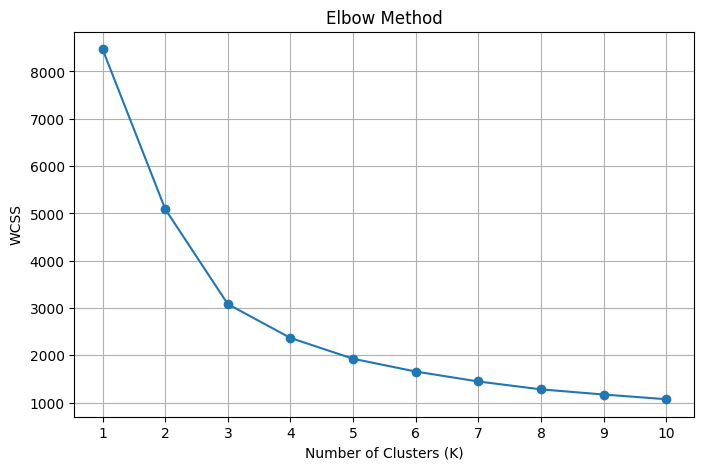

In [ ]:
wcss = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [ ]:
k = 3

kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
df['KMeans_Cluster'] = kmeans.fit_predict(X_scaled)

print(df[['QUANTITYORDERED', 'PRICEEACH',
          'SALES', 'KMeans_Cluster']].head(10))

print("\nCluster Counts:")
print(df['KMeans_Cluster'].value_counts().sort_index())

   QUANTITYORDERED  PRICEEACH    SALES  KMeans_Cluster
0               30      95.70  2871.00               2
1               34      81.35  2765.90               2
2               41      94.74  3884.34               1
3               45      83.26  3746.70               1
4               49     100.00  5205.27               1
5               36      96.66  3479.76               2
6               29      86.13  2497.77               2
7               48     100.00  5512.32               1
8               22      98.57  2168.54               2
9               41     100.00  4708.44               1

Cluster Counts:
KMeans_Cluster
0     881
1     907
2    1035
Name: count, dtype: int64


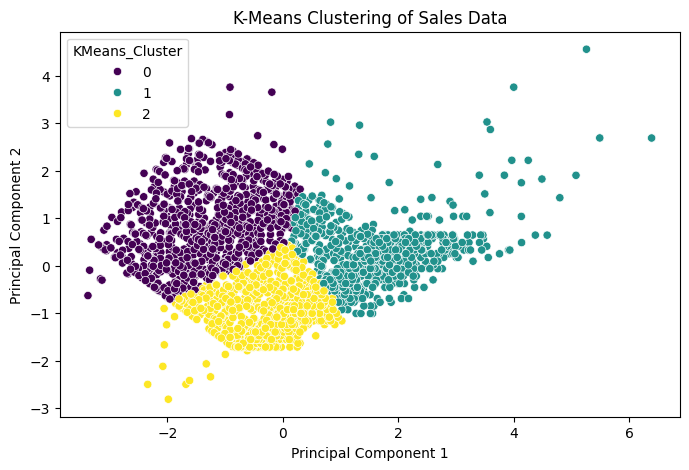

In [ ]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 5))
sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=df['KMeans_Cluster'],
    palette='viridis'
)
plt.title('K-Means Clustering of Sales Data')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.show()


In [ ]:
hierarchical = AgglomerativeClustering(n_clusters=k)
df['Hierarchical_Cluster'] = hierarchical.fit_predict(X_scaled)

print(df[['QUANTITYORDERED', 'PRICEEACH',
          'SALES', 'Hierarchical_Cluster']].head(10))

print("\nHierarchical Cluster Counts:")
print(df['Hierarchical_Cluster'].value_counts().sort_index())

   QUANTITYORDERED  PRICEEACH    SALES  Hierarchical_Cluster
0               30      95.70  2871.00                     2
1               34      81.35  2765.90                     2
2               41      94.74  3884.34                     1
3               45      83.26  3746.70                     0
4               49     100.00  5205.27                     1
5               36      96.66  3479.76                     2
6               29      86.13  2497.77                     2
7               48     100.00  5512.32                     1
8               22      98.57  2168.54                     2
9               41     100.00  4708.44                     1

Hierarchical Cluster Counts:
Hierarchical_Cluster
0    1014
1     685
2    1124
Name: count, dtype: int64


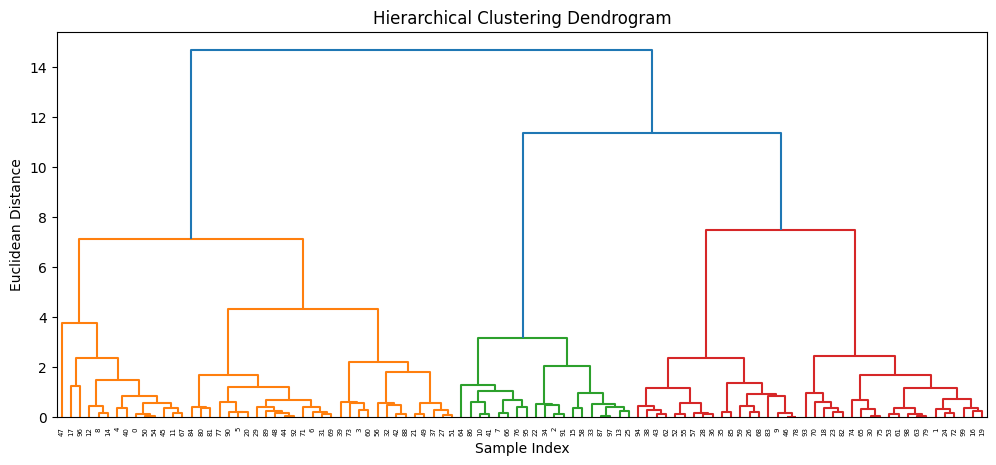

In [ ]:
sample_size = min(100, len(X_scaled))
sample_indices = np.random.default_rng(42).choice(
    len(X_scaled), size=sample_size, replace=False
)

Z = linkage(X_scaled[sample_indices], method='ward')

plt.figure(figsize=(12, 5))
dendrogram(Z)
plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Sample Index')
plt.ylabel('Euclidean Distance')
plt.show()

In [ ]:
print("K-Means Cluster Summary:")
print(df.groupby('KMeans_Cluster')[features].mean().round(2))

print("\nHierarchical Cluster Summary:")
print(df.groupby('Hierarchical_Cluster')[features].mean().round(2))

K-Means Cluster Summary:
                QUANTITYORDERED  PRICEEACH    SALES
KMeans_Cluster                                     
0                         35.13      57.13  2009.83
1                         43.85      96.64  5584.01
2                         27.39      94.87  3089.15

Hierarchical Cluster Summary:
                      QUANTITYORDERED  PRICEEACH    SALES
Hierarchical_Cluster                                     
0                               36.58      60.35  2238.07
1                               44.08      99.45  6081.75
2                               28.27      95.06  3200.38


In [ ]:
df.to_csv('sales_clustering_results.csv', index=False)

files.download('sales_clustering_results.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>